In [ ]:
# Passo 1: Importar bibliotecas necessárias
import pandas as pd
from google.colab import files

# Passo 2: Fazer upload do arquivo
uploaded = files.upload()

# Passo 3: Carregar o arquivo Excel
file_name = list(uploaded.keys())[0]
excel_file = pd.ExcelFile(file_name)


Saving base_reclamações_.xlsx to base_reclamações_ (1).xlsx


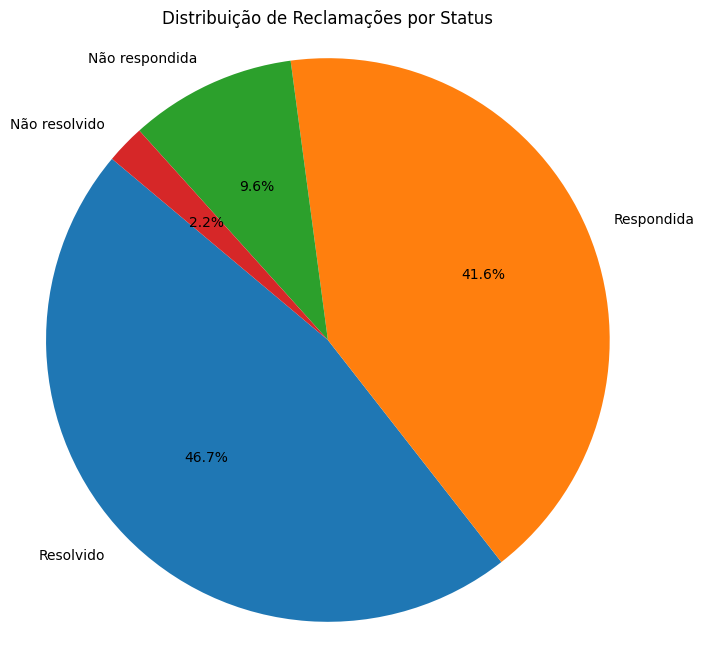

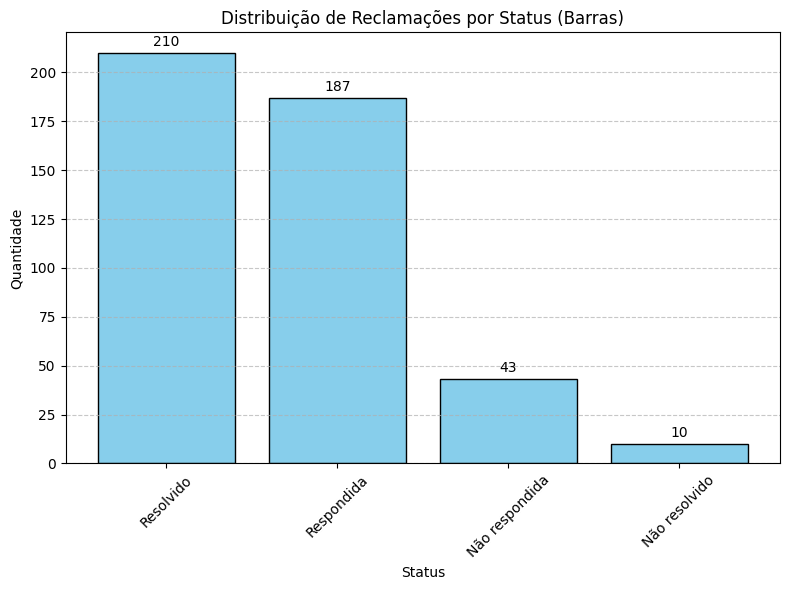

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

excel_file = pd.ExcelFile(file_name)
df = excel_file.parse('Recuperada_Planilha1')

# Conta a quantidade de cada status
status_counts = df['Status'].value_counts()

# Plota o gráfico de pizza
plt.figure(figsize=(8, 8))
plt.pie(status_counts, labels=status_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribuição de Reclamações por Status')
plt.axis('equal')
plt.show()

# --- Gráfico de Barras com rótulos ---
plt.figure(figsize=(8, 6))
bars = plt.bar(status_counts.index, status_counts.values, color='skyblue', edgecolor='black')
plt.title('Distribuição de Reclamações por Status (Barras)')
plt.xlabel('Status')
plt.ylabel('Quantidade')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adiciona os valores acima de cada barra
for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3),
                 textcoords="offset points",
                 ha='center', va='bottom')

plt.tight_layout()
plt.show()

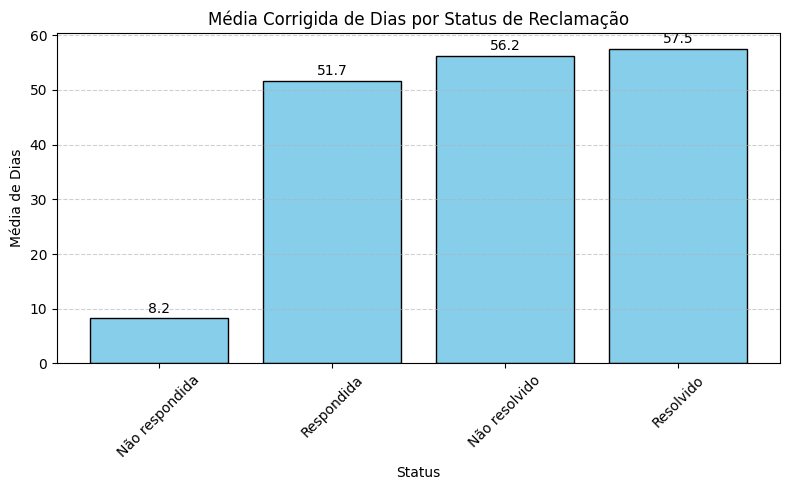

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import re

# Função para converter "Há X dias/meses" em número de dias
def converter_para_dias(texto):
    if pd.isna(texto):
        return np.nan
    texto = texto.lower()
    if "dia" in texto:
        match = re.search(r'(\d+)', texto)
        return int(match.group(1)) if match else np.nan
    elif "mês" in texto or "mes" in texto:
        match = re.search(r'(\d+)', texto)
        return int(match.group(1)) * 30 if match else np.nan
    else:
        return np.nan

# Aplica a conversão na base
df['Dias_num'] = df['Dias'].apply(converter_para_dias)

# Calcula a média por status
media_por_status = df.groupby('Status')['Dias_num'].mean().sort_values()

# Gera gráfico de barras
plt.figure(figsize=(8, 5))
bars = plt.bar(media_por_status.index, media_por_status.values, color='skyblue', edgecolor='black')

# Adiciona rótulos nas barras
for bar in bars:
    altura = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, altura + 1, f'{altura:.1f}', ha='center', fontsize=10)

plt.title('Média Corrigida de Dias por Status de Reclamação')
plt.xlabel('Status')
plt.ylabel('Média de Dias')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 46.7 MB/s eta 0:00:00


Device set to use cpu


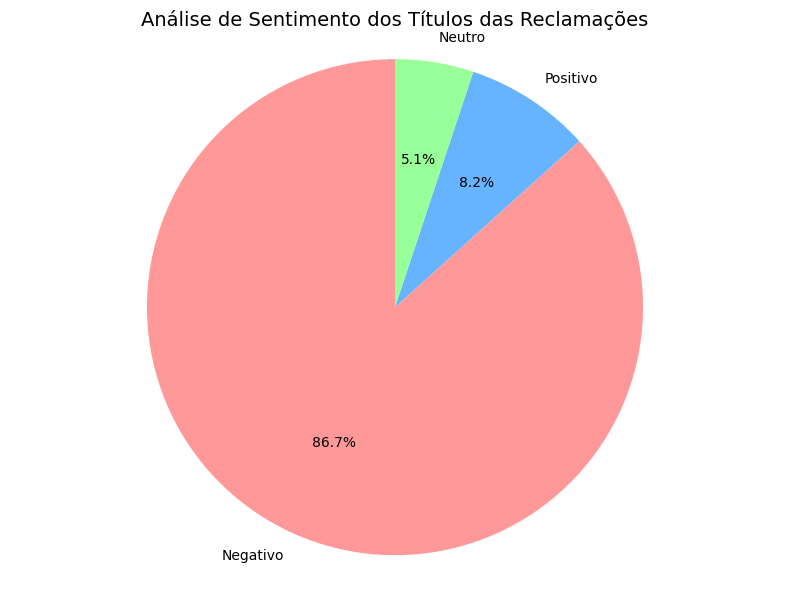

In [ ]:
# Instalar transformers
!pip install -q transformers torch

from transformers import pipeline
import pandas as pd
import matplotlib.pyplot as plt

# Carrega pipeline de análise de sentimento multilíngue
sentimento_pipeline = pipeline("sentiment-analysis", model="nlptown/bert-base-multilingual-uncased-sentiment")

# Função de análise de sentimento para português
def analyze_sentiment_pt(text):
    try:
        result = sentimento_pipeline(text[:512])[0]  # Limita a 512 tokens
        score = int(result['label'].split()[0])  # Ex: "4 stars" → 4
        if score <= 2:
            return 'Negativo'
        elif score == 3:
            return 'Neutro'
        else:
            return 'Positivo'
    except:
        return 'Neutro'

# Aplica na coluna "Título"
df['Sentimento'] = df['Título'].astype(str).apply(analyze_sentiment_pt)

# Contagem dos sentimentos
sentiment_counts = df['Sentimento'].value_counts()

# Gráfico de pizza
plt.figure(figsize=(8, 6))
plt.pie(sentiment_counts,
        labels=sentiment_counts.index,
        autopct='%1.1f%%',
        colors=['#ff9999','#66b3ff','#99ff99'],
        startangle=90)
plt.title('Análise de Sentimento dos Títulos das Reclamações', fontsize=14)
plt.axis('equal')
plt.tight_layout()
plt.show()


modules.json:   0%|          | 0.00/341 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/2.24k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/556 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

2_Dense/pytorch_model.bin:   0%|          | 0.00/1.58M [00:00<?, ?B/s]

2_Dense/model.safetensors:   0%|          | 0.00/1.58M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/114 [00:00<?, ?B/s]

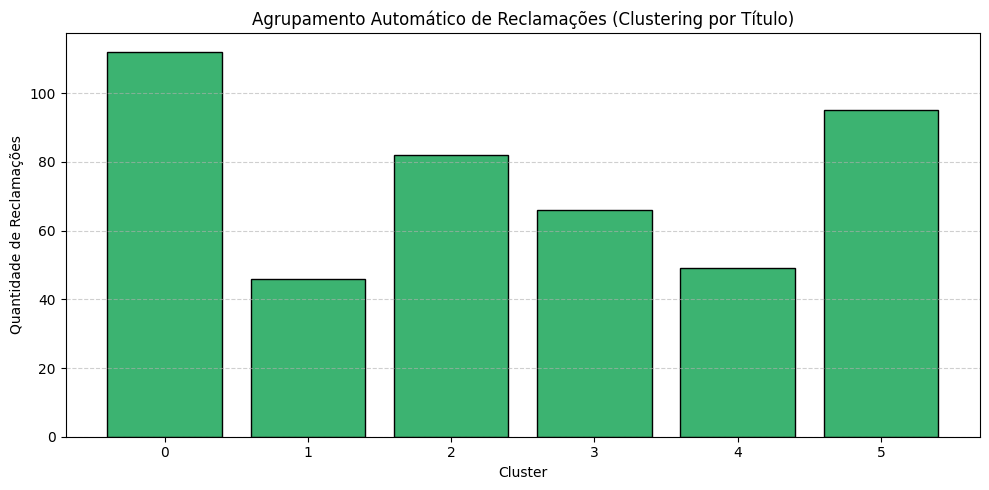


📂 Exemplos do Cluster 0:
 - Problemas recorrentes com importação de extratos, categorização errada e risco de multa injusta
 - Propaganda enganosa e péssimo Atendimento
 - Equipe incompetente e empresa desorganizada

📂 Exemplos do Cluster 1:
 - COBRANÇA CORE , OMISSÃO DE INFORMAÇÕES E ESCLARECIMENTOS A CLIENTE NA ABERTURA DE CNPJ , PREJUDICADO!
 - NAO QUEREM ME FORNECER MEU DECLARE DE IR
 - COBRANÇA INDEVIDA

📂 Exemplos do Cluster 2:
 - Cancelamento com taxas abusivas
 - Sem Suporte
 - Cobrança Indevida Mensalidade

📂 Exemplos do Cluster 3:
 - [Falta de Resposta] - Mais de 17 dias sem resposta.
 - Não cumpre o Cancelamento do Contrato
 - Contabilizei recusa-se a responder clientes. Não recomendo essa empresa!

📂 Exemplos do Cluster 4:
 - Não fizeram meu fechamento contábil até hoje, e faltam 2 semanas para declarar o IR
 - Nunca solicitem alteração contratual nenhuma
 - Descaso com minha alteração contratual

📂 Exemplos do Cluster 5:
 - Atraso na disponibilização do informe de rendime

In [ ]:
# Instalar bibliotecas necessárias
!pip install -q sentence-transformers scikit-learn

from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pandas as pd

# Carrega o modelo pré-treinado
modelo = SentenceTransformer('distiluse-base-multilingual-cased-v1')

# Extrai os títulos e gera vetoress
titulos = df['Título'].astype(str).tolist()
vetores = modelo.encode(titulos)

# Defini o número de clusters
num_clusters = 6
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
kmeans.fit(vetores)

# Mostra rótulos dos clusters atribuídos
df['Cluster'] = kmeans.labels_

# Conta quantas reclamações caíram em cada cluster
cluster_counts = df['Cluster'].value_counts().sort_index()

# Gráfico de barras dos clusters
plt.figure(figsize=(10, 5))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values, color='mediumseagreen', edgecolor='black')
plt.title('Agrupamento Automático de Reclamações (Clustering por Título)')
plt.xlabel('Cluster')
plt.ylabel('Quantidade de Reclamações')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Exibi exemplos de cada cluster
for i in range(num_clusters):
    print(f"\n📂 Exemplos do Cluster {i}:")
    exemplos = df[df['Cluster'] == i]['Título'].head(3).tolist()
    for titulo in exemplos:
        print(f" - {titulo}")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


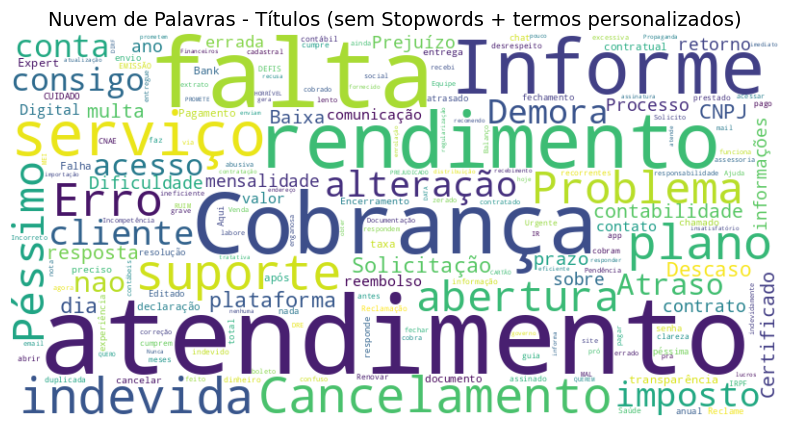

In [ ]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt
import nltk

# Baixa stopwords do NLTK
nltk.download('stopwords')
from nltk.corpus import stopwords

# Stopwords padrão em português
stopwords_pt = set(stopwords.words('portuguese'))

# Adiciona palavras específicas a serem removidas
stopwords_pt.update(['contabilizei', 'empresa'])

# Texto dos títulos
texto_titulos = ' '.join(df['Título'].dropna().astype(str).tolist())

# Gera nuvem de palavras com stopwords personalizadas
wordcloud_titulo = WordCloud(width=800, height=400, background_color='white',
                             stopwords=stopwords_pt, collocations=False).generate(texto_titulos)

# Mostra nuvem de títulos
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_titulo, interpolation='bilinear')
plt.axis('off')
plt.title('Nuvem de Palavras - Títulos (sem Stopwords + termos personalizados)', fontsize=14)
plt.show()
